<a href="https://colab.research.google.com/github/aswanth14-pixel/Machine-Learning/blob/main/Patient_Stratification_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Patient Stratification Using Clustering and Mixture Models
**Part A | Google Colab notebook**

This notebook explores physiological measurements and implements:
- K-means clustering
- Gaussian Mixture Model (GMM)
- PCA and Factor Analysis
- Hierarchical clustering with Ward's linkage
- Adjusted Rand Index (ARI) comparison between Ward clustering and GMM

> **Important:** The dataset is synthetic/educational and the clusters are not clinical diagnoses. Check the detected feature columns before running the modelling cells. If the automatic detection chooses the wrong columns, edit `feature_columns` in Step 3.

## Step 1: Import libraries

In [1]:
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.metrics import adjusted_rand_score, silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Upload and inspect the CSV
Run the cell and select the CSV you downloaded from Kaggle.

In [2]:
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file was uploaded. Please upload the dataset as a .csv file.")

# If multiple CSVs were uploaded, the first one is loaded. Change this line if needed.
file_name = csv_files[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print(f"Loaded: {file_name}")
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types and missing values:")
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}))
print("\\nNumeric summary:")
display(df.describe(include="number").T)

Saving Synthetic_patient-HealthCare-Monitoring_dataset.csv to Synthetic_patient-HealthCare-Monitoring_dataset.csv
Loaded: Synthetic_patient-HealthCare-Monitoring_dataset.csv
Dataset shape: (60000, 13)


,Patient Number,Heart Rate (bpm),SpO2 Level (%),Systolic Blood Pressure (mmHg),Diastolic Blood Pressure (mmHg),Body Temperature (°C),Fall Detection,Predicted Disease,Data Accuracy (%),Heart Rate Alert,SpO2 Level Alert,Blood Pressure Alert,Temperature Alert
0,1,98,96,120,86,38.1,No,Diabetes Mellitus,95,NORMAL,NORMAL,NORMAL,ABNORMAL
1,2,105,97,177,104,37.6,No,Heart Disease,91,ABNORMAL,NORMAL,ABNORMAL,ABNORMAL
2,3,90,85,139,57,37.0,No,Asthma,98,NORMAL,ABNORMAL,NORMAL,NORMAL
3,4,102,87,101,77,36.4,No,Asthma,87,ABNORMAL,ABNORMAL,NORMAL,NORMAL
4,5,81,95,172,119,37.7,No,Hypertension,88,NORMAL,NORMAL,ABNORMAL,ABNORMAL


\nColumn names:
['Patient Number', 'Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Fall Detection', 'Predicted Disease', 'Data Accuracy (%)', 'Heart Rate Alert', 'SpO2 Level Alert', 'Blood Pressure Alert', 'Temperature Alert']
\nData types and missing values:


,dtype,missing_values,missing_percent
Patient Number,int64,0,0.0
Heart Rate (bpm),int64,0,0.0
SpO2 Level (%),int64,0,0.0
Systolic Blood Pressure (mmHg),int64,0,0.0
Diastolic Blood Pressure (mmHg),int64,0,0.0
Body Temperature (°C),float64,0,0.0
Fall Detection,object,0,0.0
Predicted Disease,object,0,0.0
Data Accuracy (%),int64,0,0.0
Heart Rate Alert,object,0,0.0


\nNumeric summary:


,count,mean,std,min,25%,50%,75%,max
Patient Number,60000.0,30000.500000,17320.652413,1.0,15000.75,30000.5,45000.25,60000.0
Heart Rate (bpm),60000.0,94.571150,18.376105,50.0,82.00,95.0,106.00,139.0
SpO2 Level (%),60000.0,94.553433,3.843543,84.0,92.00,96.0,98.00,100.0
Systolic Blood Pressure (mmHg),60000.0,139.152733,26.933776,90.0,116.00,138.0,161.00,199.0
Diastolic Blood Pressure (mmHg),60000.0,88.954633,17.856562,50.0,75.00,89.0,102.00,130.0
Body Temperature (°C),60000.0,37.121432,0.626535,35.0,36.70,37.0,37.60,39.3
Data Accuracy (%),60000.0,92.511417,4.609298,85.0,89.00,93.0,97.00,100.0


## Step 3: Select physiological features
The code tries to detect common names for heart rate, blood pressure, and oxygen saturation. **Review the printed result.** If the names are incorrect or some required features are missing, manually set `feature_columns` to the matching column names in your dataset.

For this assignment, use continuous physiological columns such as heart rate, systolic/diastolic blood pressure, and SpO₂. Avoid patient IDs and text labels as clustering features.

In [3]:
# Automatic column detection using common column-name variations.
column_lookup = {str(c).strip().lower().replace(" ", "_"): c for c in df.columns}

aliases = {
    "heart_rate": [
        "heart_rate", "heartrate", "hr", "pulse", "pulse_rate", "heart_rate_bpm"
    ],
    "systolic_bp": [
        "systolic_bp", "systolic_blood_pressure", "sbp", "blood_pressure_systolic",
        "systolic"
    ],
    "diastolic_bp": [
        "diastolic_bp", "diastolic_blood_pressure", "dbp", "blood_pressure_diastolic",
        "diastolic"
    ],
    "oxygen_saturation": [
        "spo2", "sp_o2", "oxygen_saturation", "oxygen_saturation_percent",
        "blood_oxygen", "o2_saturation", "spo2_percent"
    ]
}

detected = []
for concept, names in aliases.items():
    found = None
    for alias in names:
        if alias in column_lookup:
            found = column_lookup[alias]
            break
    if found is not None:
        detected.append(found)

# Fallback: numeric columns, excluding columns that look like identifiers or labels.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
excluded_words = ["id", "patient", "record", "index", "label", "class", "diagnos"]
fallback_cols = [
    c for c in numeric_cols
    if not any(word in str(c).lower() for word in excluded_words)
]

feature_columns = list(dict.fromkeys(detected))
if len(feature_columns) < 2:
    feature_columns = fallback_cols[:]

print("Automatically detected physiological columns:", detected)
print("Suggested feature columns:", feature_columns)
print("\\nAll numeric columns:", numeric_cols)

# EDIT THIS LIST IF NECESSARY, using exact names from df.columns.tolist().
# Example: feature_columns = ["Heart Rate", "Systolic BP", "Diastolic BP", "SpO2"]

if len(feature_columns) < 2:
    raise ValueError("Could not find at least two suitable numeric features. Set feature_columns manually.")

print("\\nFeatures currently selected:")
print(feature_columns)

Automatically detected physiological columns: []
Suggested feature columns: ['Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Data Accuracy (%)']
\nAll numeric columns: ['Patient Number', 'Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Data Accuracy (%)']
\nFeatures currently selected:
['Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Data Accuracy (%)']


## Step 4: Clean and standardize the data

In [4]:
# Convert selected features to numeric; invalid values become missing.
X_raw = df[feature_columns].copy()
for col in feature_columns:
    X_raw[col] = pd.to_numeric(X_raw[col], errors="coerce")

# Remove columns that have no usable numeric values.
usable_columns = [c for c in X_raw.columns if X_raw[c].notna().any()]
X_raw = X_raw[usable_columns]
feature_columns = usable_columns

if X_raw.shape[1] < 2:
    raise ValueError("At least two usable numeric features are required.")

# Median imputation handles missing measurements.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

# Standardize features because they use different units (e.g., BPM and mmHg).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Rows used:", X_scaled.shape[0])
print("Features used:", feature_columns)
print("Missing values after imputation:", int(np.isnan(X_scaled).sum()))
print("Standardized data shape:", X_scaled.shape)

Rows used: 60000
Features used: ['Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Data Accuracy (%)']
Missing values after imputation: 0
Standardized data shape: (60000, 6)


## Step 5: Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
Heart Rate (bpm),60000.0,94.571150,18.376105,50.0,82.0,95.0,106.0,139.0
SpO2 Level (%),60000.0,94.553433,3.843543,84.0,92.0,96.0,98.0,100.0
Systolic Blood Pressure (mmHg),60000.0,139.152733,26.933776,90.0,116.0,138.0,161.0,199.0
Diastolic Blood Pressure (mmHg),60000.0,88.954633,17.856562,50.0,75.0,89.0,102.0,130.0
Body Temperature (°C),60000.0,37.121432,0.626535,35.0,36.7,37.0,37.6,39.3
Data Accuracy (%),60000.0,92.511417,4.609298,85.0,89.0,93.0,97.0,100.0


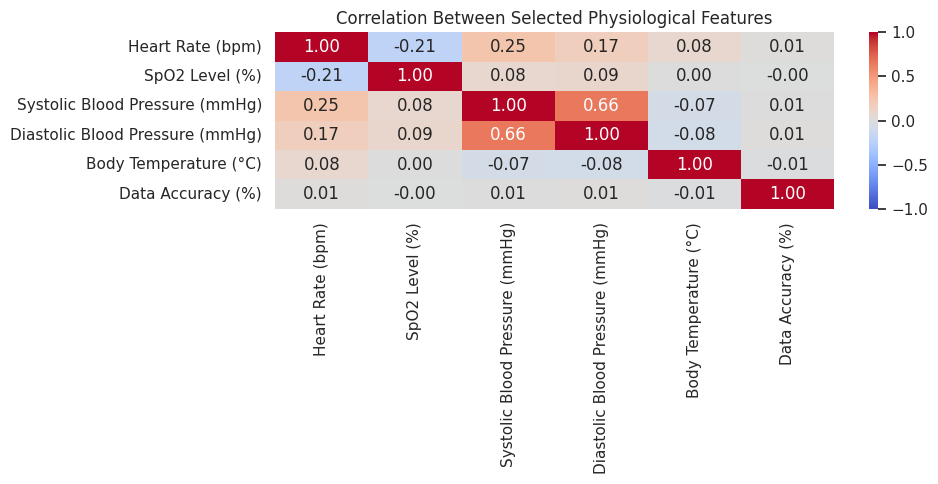

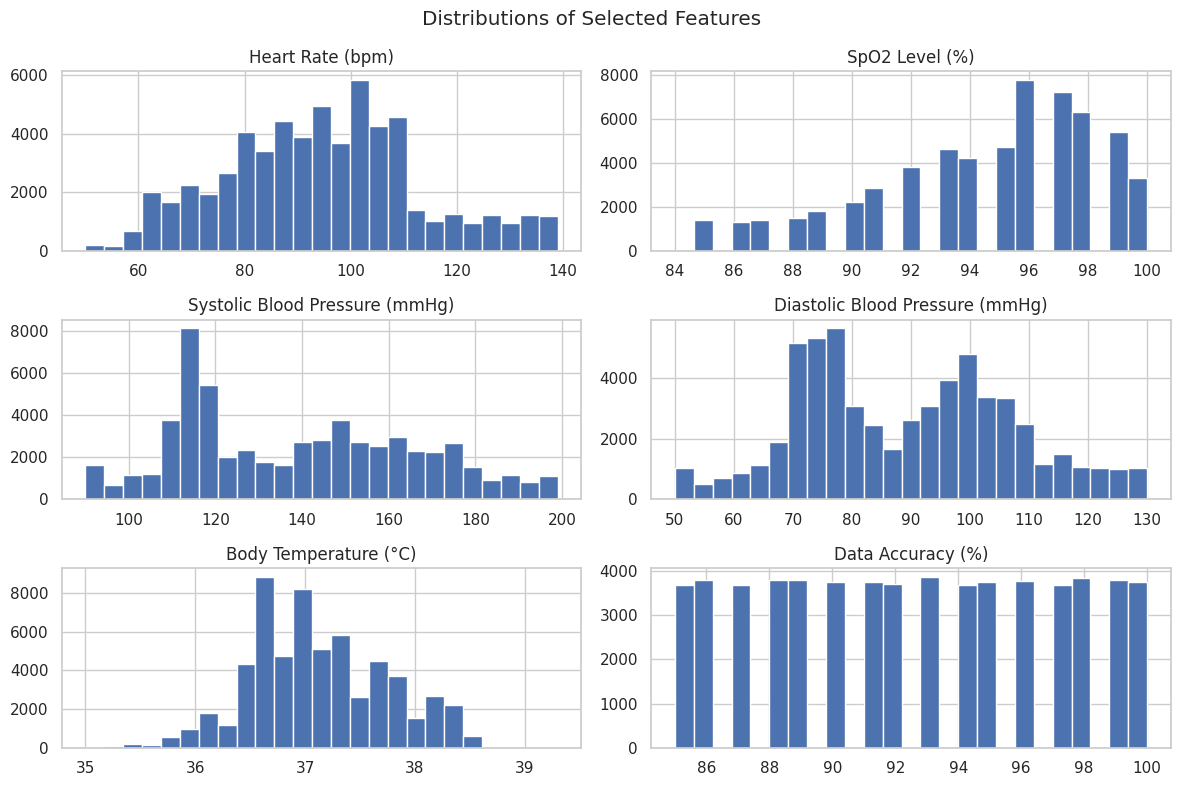

In [5]:
display(pd.DataFrame(X_imputed, columns=feature_columns).describe().T)

plt.figure(figsize=(10, 5))
sns.heatmap(pd.DataFrame(X_imputed, columns=feature_columns).corr(),
            annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Selected Physiological Features")
plt.tight_layout()
plt.show()

# Plot feature distributions
pd.DataFrame(X_imputed, columns=feature_columns).hist(figsize=(12, 8), bins=25)
plt.suptitle("Distributions of Selected Features")
plt.tight_layout()
plt.show()

## Step 6: Choose a cluster count
We use the elbow curve and silhouette score as practical guides. For this assignment, we will use **4 clusters** as a starting point, but the data may support a different number. These clusters are mathematical groupings, not medically validated risk categories.

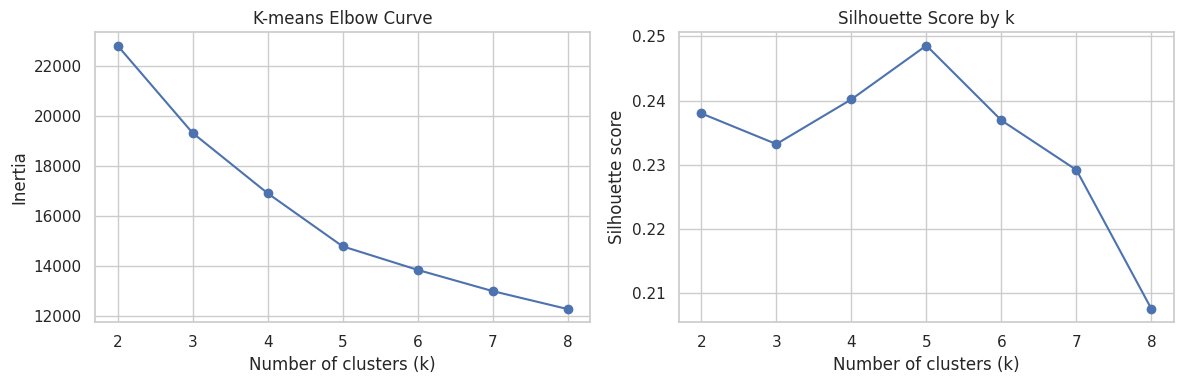

Selected cluster count: 4


In [6]:
# Use a sample for cluster-count diagnostics if the dataset is large.
rng = np.random.default_rng(RANDOM_STATE)
diagnostic_n = min(5000, X_scaled.shape[0])
diagnostic_idx = rng.choice(X_scaled.shape[0], size=diagnostic_n, replace=False)
X_diag = X_scaled[diagnostic_idx]

max_k = min(8, max(2, X_diag.shape[0] - 1))
ks = list(range(2, max_k + 1))
inertias, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_diag)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_diag, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("K-means Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

N_CLUSTERS = 4
print("Selected cluster count:", N_CLUSTERS)

## Step 7: K-means clustering

In [7]:
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-means cluster sizes:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index())

kmeans_profile = pd.DataFrame(X_imputed, columns=feature_columns).assign(cluster=kmeans_labels)
print("Mean feature values by K-means cluster:")
display(kmeans_profile.groupby("cluster")[feature_columns].mean().round(2))

K-means cluster sizes:


,count
cluster,
0,11337
1,23248
2,12671
3,12744


Mean feature values by K-means cluster:


,Heart Rate (bpm),SpO2 Level (%),Systolic Blood Pressure (mmHg),Diastolic Blood Pressure (mmHg),Body Temperature (°C),Data Accuracy (%)
cluster,,,,,,
0,99.88,88.71,124.94,79.37,36.93,92.56
1,102.17,95.46,166.02,105.96,36.97,92.60
2,74.72,97.47,115.04,74.79,36.77,92.50
3,95.72,95.20,126.75,80.55,37.92,92.33


## Step 8: Gaussian Mixture Model (GMM)

In [8]:
gmm = GaussianMixture(
    n_components=N_CLUSTERS,
    covariance_type="full",
    random_state=RANDOM_STATE,
    n_init=3,
    reg_covar=1e-6
)
gmm.fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
gmm_probabilities = gmm.predict_proba(X_scaled)

print("GMM converged:", gmm.converged_)
print("GMM cluster sizes:")
display(pd.Series(gmm_labels, name="cluster").value_counts().sort_index())

print("First five rows of GMM membership probabilities:")
display(pd.DataFrame(
    gmm_probabilities[:5],
    columns=[f"Cluster_{i}_probability" for i in range(N_CLUSTERS)]
).round(3))

gmm_profile = pd.DataFrame(X_imputed, columns=feature_columns).assign(cluster=gmm_labels)
print("Mean feature values by GMM cluster:")
display(gmm_profile.groupby("cluster")[feature_columns].mean().round(2))

GMM converged: True
GMM cluster sizes:


,count
cluster,
0,11980
1,11034
2,23723
3,13263


First five rows of GMM membership probabilities:


,Cluster_0_probability,Cluster_1_probability,Cluster_2_probability,Cluster_3_probability
0,0.0,0.000,1.000,0.000
1,0.0,0.294,0.004,0.702
2,0.0,0.000,1.000,0.000
3,0.0,0.000,1.000,0.000
4,0.0,0.999,0.000,0.000


Mean feature values by GMM cluster:


,Heart Rate (bpm),SpO2 Level (%),Systolic Blood Pressure (mmHg),Diastolic Blood Pressure (mmHg),Body Temperature (°C),Data Accuracy (%)
cluster,,,,,,
0,74.44,97.49,114.51,74.53,36.75,92.49
1,82.89,95.39,172.74,112.82,37.00,92.48
2,96.96,92.17,124.54,79.16,37.43,92.45
3,118.20,95.47,159.61,99.65,37.00,92.66


## Step 9: PCA for dimensionality reduction
PCA selects a smaller number of components that retain a target amount of variance. We use **95% cumulative explained variance** as a common working threshold.

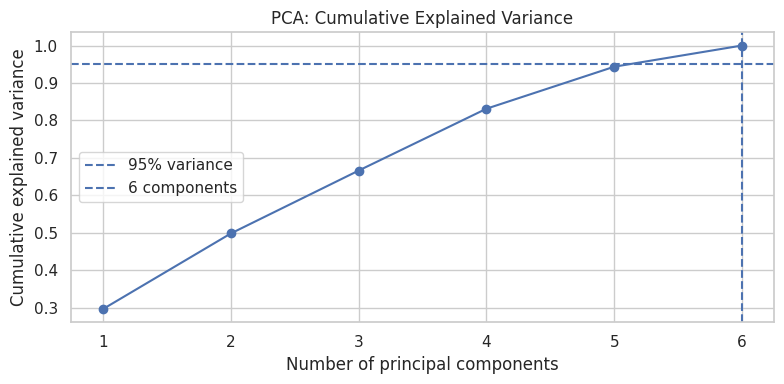

Number of original features: 6
Minimum PCA components for at least 95% variance: 6
Variance retained: 1.000


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.2964,0.2964
1,PC2,0.2018,0.4982
2,PC3,0.1679,0.6660
3,PC4,0.1652,0.8312
4,PC5,0.1122,0.9434
5,PC6,0.0566,1.0000


In [9]:
pca_full = PCA()
pca_full.fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_pca = int(np.argmax(cumulative_variance >= 0.95) + 1)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.axvline(n_pca, linestyle="--", label=f"{n_pca} components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

pca = PCA(n_components=n_pca)
X_pca = pca.fit_transform(X_scaled)

print(f"Number of original features: {X_scaled.shape[1]}")
print(f"Minimum PCA components for at least 95% variance: {n_pca}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.3f}")
display(pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(n_pca)],
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance": np.cumsum(pca.explained_variance_ratio_)
}).round(4))

## Step 10: Factor Analysis
Factor Analysis models observed measurements as combinations of latent factors plus feature-specific noise. Unlike PCA, it does **not** directly choose components by maximizing total variance, so we report its factor loadings and compare a small range of factor counts.

In [ ]:
max_factors = min(X_scaled.shape[1], 6)
fa_results = []

for n_factors in range(1, max_factors + 1):
    fa = FactorAnalysis(n_components=n_factors, random_state=RANDOM_STATE)
    fa.fit(X_scaled)
    # Approximate reconstruction error helps compare factor counts.
    X_reconstructed = fa.transform(X_scaled) @ fa.components_ + fa.mean_
    mse = float(np.mean((X_scaled - X_reconstructed) ** 2))
    fa_results.append({"n_factors": n_factors, "reconstruction_mse": mse})

fa_results_df = pd.DataFrame(fa_results)
display(fa_results_df.round(4))

# Fit a compact factor model; use up to 3 factors, bounded by feature count.
n_factors_final = min(3, X_scaled.shape[1])
factor_analysis = FactorAnalysis(n_components=n_factors_final, random_state=RANDOM_STATE)
X_factors = factor_analysis.fit_transform(X_scaled)

loadings = pd.DataFrame(
    factor_analysis.components_.T,
    index=feature_columns,
    columns=[f"Factor_{i+1}" for i in range(n_factors_final)]
)
print(f"Factor Analysis fitted with {n_factors_final} factors.")
print("Factor loadings:")
display(loadings.round(3))

plt.figure(figsize=(8, max(3, 0.45 * len(feature_columns))))
sns.heatmap(loadings, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Factor Analysis Loadings")
plt.tight_layout()
plt.show()

## Step 11: Ward hierarchical clustering vs. GMM using ARI
Ward hierarchical clustering can require substantial memory/time because it considers pairwise distances. To keep Colab responsive, this comparison uses a reproducible sample of up to 3,000 records. GMM is fitted on that same sample so the ARI comparison is fair.

ARI measures agreement between two partitions, adjusted for chance:
- `1.0` means identical partitions.
- Around `0.0` means agreement similar to chance.
- Negative values mean less agreement than expected by chance.

Here, GMM is the reference partition because no ground-truth labels are assumed. This evaluates agreement between algorithms, not clinical accuracy.

In [10]:
comparison_n = min(3000, X_scaled.shape[0])
comparison_rng = np.random.default_rng(RANDOM_STATE)
comparison_idx = comparison_rng.choice(X_scaled.shape[0], size=comparison_n, replace=False)
X_compare = X_scaled[comparison_idx]

# Fit GMM on the same comparison sample.
gmm_compare = GaussianMixture(
    n_components=N_CLUSTERS,
    covariance_type="full",
    random_state=RANDOM_STATE,
    n_init=3,
    reg_covar=1e-6
)
gmm_compare_labels = gmm_compare.fit_predict(X_compare)

ward = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
ward_labels = ward.fit_predict(X_compare)

ari = adjusted_rand_score(gmm_compare_labels, ward_labels)
print(f"Records used for Ward/GMM comparison: {comparison_n}")
print(f"Adjusted Rand Index (Ward vs GMM): {ari:.4f}")

comparison_counts = pd.DataFrame({
    "GMM_cluster": gmm_compare_labels,
    "Ward_cluster": ward_labels
})
display(pd.crosstab(comparison_counts["GMM_cluster"], comparison_counts["Ward_cluster"],
                    rownames=["GMM"], colnames=["Ward"]))

Records used for Ward/GMM comparison: 3000
Adjusted Rand Index (Ward vs GMM): 0.5308


Ward,0,1,2,3
GMM,,,,
0,552,0,2,9
1,71,5,569,543
2,0,615,0,0
3,614,0,12,8


## Step 12: Visualize clusters with PCA

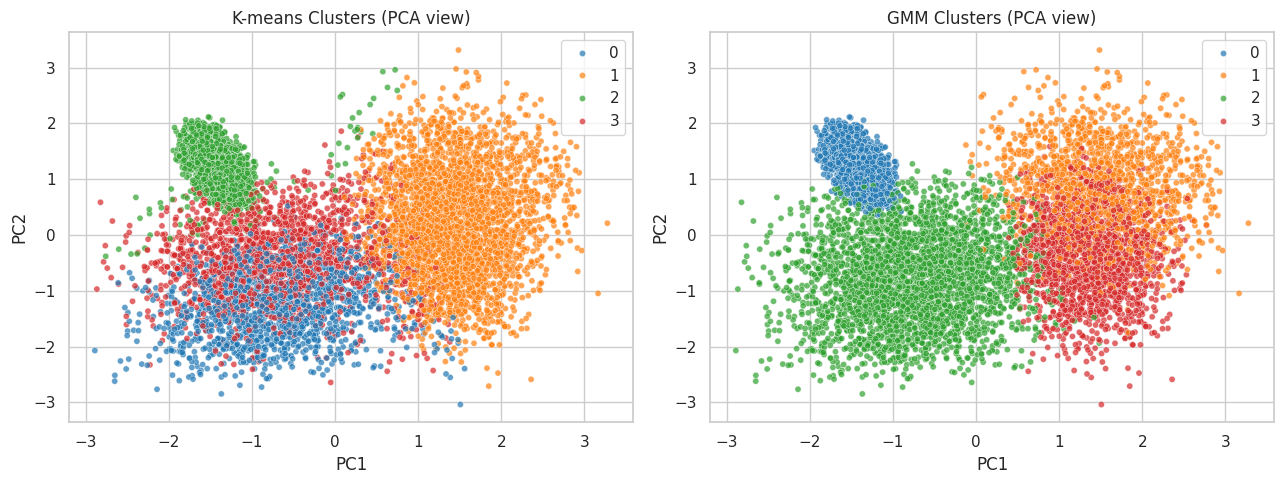

In [11]:
# Plot the first two principal components. If only one component exists,
# the second axis will be filled with zeros.
if X_pca.shape[1] >= 2:
    plot_pcs = X_pca[:, :2]
    x_label, y_label = "PC1", "PC2"
else:
    plot_pcs = np.column_stack([X_pca[:, 0], np.zeros(X_pca.shape[0])])
    x_label, y_label = "PC1", "No second component"

plot_n = min(8000, len(plot_pcs))
plot_idx = np.random.default_rng(RANDOM_STATE).choice(len(plot_pcs), plot_n, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(
    x=plot_pcs[plot_idx, 0], y=plot_pcs[plot_idx, 1],
    hue=kmeans_labels[plot_idx], palette="tab10", s=20, alpha=0.7, ax=axes[0],
    legend="brief"
)
axes[0].set_title("K-means Clusters (PCA view)")
axes[0].set_xlabel(x_label)
axes[0].set_ylabel(y_label)

sns.scatterplot(
    x=plot_pcs[plot_idx, 0], y=plot_pcs[plot_idx, 1],
    hue=gmm_labels[plot_idx], palette="tab10", s=20, alpha=0.7, ax=axes[1],
    legend="brief"
)
axes[1].set_title("GMM Clusters (PCA view)")
axes[1].set_xlabel(x_label)
axes[1].set_ylabel(y_label)

plt.tight_layout()
plt.show()

## Step 13: Summary of results

In [13]:
# Step 13: Summary of Results

# Ensure the Factor Analysis variable exists
if "n_factors_final" not in globals():
    n_factors_final = min(3, X_scaled.shape[1])

summary = pd.DataFrame({
    "Item": [
        "Number of records",
        "Number of selected features",
        "K-means clusters",
        "GMM components",
        "PCA components for >=95% variance",
        "Factor Analysis factors fitted",
        "Ward vs GMM ARI (sample)"
    ],
    "Result": [
        X_scaled.shape[0],
        len(feature_columns),
        N_CLUSTERS,
        N_CLUSTERS,
        n_pca,
        n_factors_final,
        round(float(ari), 4)
    ]
})

display(summary)

print("\nInterpretation:")
print("- K-means groups records by their nearest centroid.")
print("- GMM assigns probabilistic cluster memberships.")
print("- PCA reduces dimensions while retaining at least 95% variance.")
print("- Factor Analysis identifies latent factors.")
print("- Ward clustering builds hierarchical groups.")
print("- ARI measures agreement between Ward and GMM clusters.")
print("\nNotebook complete!")

,Item,Result
0,Number of records,60000.0000
1,Number of selected features,6.0000
2,K-means clusters,4.0000
3,GMM components,4.0000
4,PCA components for >=95% variance,6.0000
5,Factor Analysis factors fitted,3.0000
6,Ward vs GMM ARI (sample),0.5308



Interpretation:
- K-means groups records by their nearest centroid.
- GMM assigns probabilistic cluster memberships.
- PCA reduces dimensions while retaining at least 95% variance.
- Factor Analysis identifies latent factors.
- Ward clustering builds hierarchical groups.
- ARI measures agreement between Ward and GMM clusters.

Notebook complete!
